# Burchardt, Varkevisser & Spierings (2025) data

In [1]:
import os
from dotenv import load_dotenv
from pathlib import Path
import pandas as pd
import sys
sys.path.append('../')
from src.rhythm_types import aggregate_units
from src.data import save_units

# Load location of Burchardt et al data from env file
load_dotenv()
if not os.getenv("BVS_DIR"):
    raise Exception("BVS_DIR environment variable not set")
DATA_DIR = Path(os.getenv("BVS_DIR"))

ROOT_DIR = Path('.').resolve().parent
DATASET_ID = 'bvs' # Burchardt, Varkevisser, Spierings
OUTPUT_DIR = ROOT_DIR / 'data'

## Filter and clean up

In [2]:
recordings = pd.read_csv(DATA_DIR / "recordings.csv", index_col=0).sort_values(['bird_id', 'tier', 'motif_num'])
recordings['bird_id'] = recordings['bird_id'].astype(str) 
recordings.head()

# Filter out bird 129 in the role of tutee2 (only keep its role tutee1)
is_bird_129 = recordings['bird_id'] == '129'
is_tutee_2 = recordings['tutee_num'] == 2
recordings = recordings[~is_bird_129 | ~is_tutee_2]

In [3]:
# Update the bird_ids of birds that are both tutor and tutee:
# add a -tutee or -tutor suffix to differentiate them
for bird_id in recordings['bird_id'].unique():
    bird_recs = recordings.query(f'bird_id == "{bird_id}"')
    if len(bird_recs['role'].unique()) > 1:
        print(bird_id)
        
        is_bird = recordings['bird_id'] == bird_id
        is_tutor = recordings['role'] == 'tutor'
        idx = recordings[is_bird & is_tutor].index
        recordings.loc[idx, 'bird_id'] = f"{bird_id}-tutor"

        is_tutee = recordings['role'] == 'tutee'
        idx = recordings[is_bird & ~is_tutor].index
        recordings.loc[idx, 'bird_id'] = f"{bird_id}-tutee"

214
218
227


In [4]:
level_to_tier = dict(elem="elements", syll="syllables")

def iter_chunks(level, updates=[]):
    tier = level_to_tier[level]
    subset = recordings[recordings['tier'] == tier]
    updates = pd.DataFrame(updates)
    for bird_id in subset['bird_id'].unique():
        bird_recs = subset[subset['bird_id'] == bird_id]
        bird_updates = updates.query(f'bird_id=="{bird_id}"')
        for i, rec in bird_recs.iterrows():
            chunk_df = pd.read_csv(DATA_DIR / Path(rec['path']), sep=";")
            chunk_idx = int(rec['motif_num'])
                
            if len(bird_updates) > 0:
                matches = bird_updates.query(f'chunk_idx=={chunk_idx}')
                if len(matches) > 0:
                    for action in matches['action']:
                        print(f'Updating bird {bird_id}, chunk {chunk_idx}')
                        chunk_df = action(chunk_df)

            yield dict(
                chunk_df=chunk_df, 
                start_col='tmin',
                end_col='tmax',
                label_col='text',
                bird_id=f"bvs-{bird_id}",
                chunk_idx=chunk_idx
            )

In [5]:
def replace_label(index, new_label):
    def replacer(chunk_df):
        m = chunk_df.copy()
        m.iloc[index, m.columns.get_loc('text')] = new_label
        return m
    return replacer

In [6]:
# Get all units
elem_updates = pd.DataFrame([
    dict(bird_id='140', chunk_idx=3, action=replace_label(5, 'i')),
    dict(bird_id='140', chunk_idx=3, action=replace_label(6, 'j')),
    dict(bird_id='147', chunk_idx=5, action=replace_label(8, 'k')),
    dict(bird_id='205', chunk_idx=8, action=replace_label(3, 'd')),
    dict(bird_id='205', chunk_idx=8, action=replace_label(4, 'd')),
    dict(bird_id='205', chunk_idx=8, action=replace_label(5, 'e')),
    dict(bird_id='212', chunk_idx=2, action=replace_label(5, 'f')),

    dict(bird_id='675', chunk_idx=9, action=replace_label(5, 'd')),
    dict(bird_id='675', chunk_idx=9, action=replace_label(6, 'e')),
    dict(bird_id='675', chunk_idx=9, action=replace_label(7, 'f')),
    dict(bird_id='675', chunk_idx=9, action=replace_label(8, 'g')),

    dict(bird_id='881', chunk_idx=4, action=replace_label(7, 'g')),
    dict(bird_id='881', chunk_idx=4, action=replace_label(8, 'h')),
    dict(bird_id='881', chunk_idx=4, action=replace_label(9, 'i')),
    dict(bird_id='881', chunk_idx=4, action=replace_label(10, 'j')),
    dict(bird_id='881', chunk_idx=4, action=replace_label(11, 'k')),
    
    dict(bird_id='441', chunk_idx=10, action=replace_label(12, 'p')),
])
elem_units = aggregate_units(iter_chunks('elem', elem_updates), level='elem')

Updating bird 140, chunk 3
Updating bird 140, chunk 3
Updating bird 147, chunk 5


Updating bird 205, chunk 8
Updating bird 205, chunk 8
Updating bird 205, chunk 8


Updating bird 212, chunk 2


Skipping bird bvs-368, chunk 9: no annotated units


Updating bird 441, chunk 10
Updating bird 675, chunk 9
Updating bird 675, chunk 9
Updating bird 675, chunk 9
Updating bird 675, chunk 9


Skipping bird bvs-879, chunk 10: no annotated units
Updating bird 881, chunk 4
Updating bird 881, chunk 4
Updating bird 881, chunk 4
Updating bird 881, chunk 4
Updating bird 881, chunk 4


In [7]:
def delete_label(index):
    def deleter(chunk_df):
        m = chunk_df.copy().drop([index])
        return m
    return deleter

In [8]:
# Get all units
syll_updates = pd.DataFrame([
    dict(bird_id='129', chunk_idx=10, action=delete_label(0)),
    dict(bird_id='213', chunk_idx=4, action=replace_label(2, 'D')),
    dict(bird_id='213', chunk_idx=4, action=replace_label(3, 'E')),
    dict(bird_id='230', chunk_idx=3, action=replace_label(4, 'D')),
    dict(bird_id='881', chunk_idx=9, action=replace_label(6, 'G')),
    dict(bird_id='441', chunk_idx=1, action=replace_label(3, 'F')),
], columns=['bird_id', 'chunk_idx', 'action'])
syll_units = aggregate_units(iter_chunks('syll', syll_updates), level='syll')

Updating bird 129, chunk 10
Cannot extract gap IOIs from 0 gap(s).
Cannot extract gap IOIs from 0 gap(s).
Cannot extract gap IOIs from 0 gap(s).
Cannot extract gap IOIs from 0 gap(s).
Cannot extract gap IOIs from 0 gap(s).
Cannot extract gap IOIs from 0 gap(s).
Cannot extract gap IOIs from 0 gap(s).
Cannot extract gap IOIs from 0 gap(s).
Cannot extract gap IOIs from 0 gap(s).
Cannot extract gap IOIs from 0 gap(s).


Cannot extract gap IOIs from 1 gap(s).
Updating bird 213, chunk 4
Updating bird 213, chunk 4
Cannot extract gap IOIs from 1 gap(s).
Cannot extract gap IOIs from 1 gap(s).
Cannot extract gap IOIs from 1 gap(s).
Cannot extract gap IOIs from 1 gap(s).
Cannot extract gap IOIs from 1 gap(s).
Cannot extract gap IOIs from 1 gap(s).
Cannot extract gap IOIs from 1 gap(s).
Cannot extract gap IOIs from 1 gap(s).
Cannot extract gap IOIs from 1 gap(s).
Cannot extract gap IOIs from 1 gap(s).
Skipping bird bvs-218-tutee, chunk 2: no annotated units


Cannot extract gap IOIs from 1 gap(s).
Updating bird 230, chunk 3


Updating bird 441, chunk 1
Cannot extract gap IOIs from 1 gap(s).
Cannot extract gap IOIs from 1 gap(s).
Cannot extract gap IOIs from 1 gap(s).
Cannot extract gap IOIs from 1 gap(s).


Cannot extract gap IOIs from 1 gap(s).
Cannot extract gap IOIs from 1 gap(s).
Cannot extract gap IOIs from 1 gap(s).
Skipping bird bvs-879, chunk 10: no annotated units
Updating bird 881, chunk 9


In [9]:
# Save
for rhythm_type, units in {**elem_units, **syll_units}.items():
    save_units(units, rhythm_type, DATASET_ID, OUTPUT_DIR)

## Predict unit labels

In [10]:
import numpy as np

from src.data import load_units
from src.pipeline.predict_bird_ids import predict_bird_ids
from src.pipeline.fit_hmms import get_output_dir
from src.viz.changepoints import plot_changepoints
from src.hmm import load_fit
from src.metrics.permutation import shuffle_labels_within_chunk

from src.constants import DATASETS

Importing the dtw module. When using in academic works please cite:
  T. Giorgino. Computing and Visualizing Dynamic Time Warping Alignments in R: The dtw Package.
  J. Stat. Soft., doi:10.18637/jss.v031.i07.



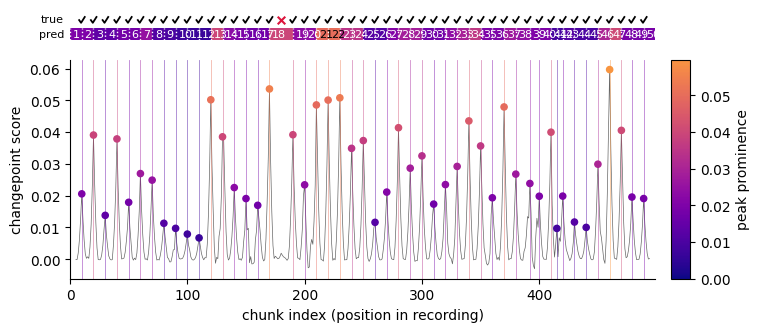

In [11]:
# Illustration
units = load_units('bvs', 'syll_ioi', use_milliseconds=False)
units = units[~units['bird_id'].str.endswith('-tutee')]
result = predict_bird_ids(units, half_window=5, min_gap=5, id_prefix='bvs-pred-')
fig, ax_tl, ax = plot_changepoints(
    result,
    result['n_chunks'],
    true_breakpoints=result['true_breakpoints'],
    tolerance=5,
)
ax.set_xlabel('chunk index (position in recording)');

In [12]:
# Add bird_id_pred, label_pred, and label_shuffle
for rhythm_type in DATASETS['bvs']['rhythm_types']:
    # Seeded by rhythm type, so the shuffle doesn't depend on loop order
    rng = np.random.default_rng([0, *rhythm_type.encode()])

    # Load current units
    units = load_units('bvs', rhythm_type, use_milliseconds=False)

    # Bird id predictions, for the 50 analysed birds (without the duplicate tutee roles)
    analysed = ~units['bird_id'].str.endswith('-tutee')
    result = predict_bird_ids(units[analysed], half_window=5, min_gap=5, id_prefix='bvs-pred-')
    units.loc[analysed, 'bird_id_pred'] = result['bird_id_pred']

    # Label predictions
    for bird_id, bird_group in units.groupby('bird_id'):
        try:
            path = get_output_dir(DATASET_ID, rhythm_type) / f"{bird_id}.joblib"
            result = load_fit(path)
            # The fit lists the chunks in chunk order, so the units must be too.
            assert bird_group['chunk_idx'].is_monotonic_increasing
            units.loc[bird_group.index, 'label_pred'] = np.concatenate(result['labels'])
        except Exception as e:
            print(bird_id, e)

    # Add one example of shuffled labels
    units['label_shuffle'] = shuffle_labels_within_chunk(
        units, rng, by=['bird_id', 'chunk_idx'], label_col='label',
    )['label']

    # Save units
    save_units(units, rhythm_type, 'bvs', OUTPUT_DIR)